<a href="https://colab.research.google.com/github/arzaa-cali/DATA-SCIENCE/blob/main/tutorial03.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np

In [2]:
from google.colab import drive
drive.mount('/content/drive') # need for the google drive to connect or can do it manually by clicking on files and mount

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
import matplotlib.pyplot as plt

***1. Find some real dataset. Load it on Colab. Try to visualize some of it***

In [4]:
df = pd.read_csv("/content/drive/MyDrive/DATA-SCIENCE-TUTORIAL/Dataset/roblox_games.csv") # df = dataframe

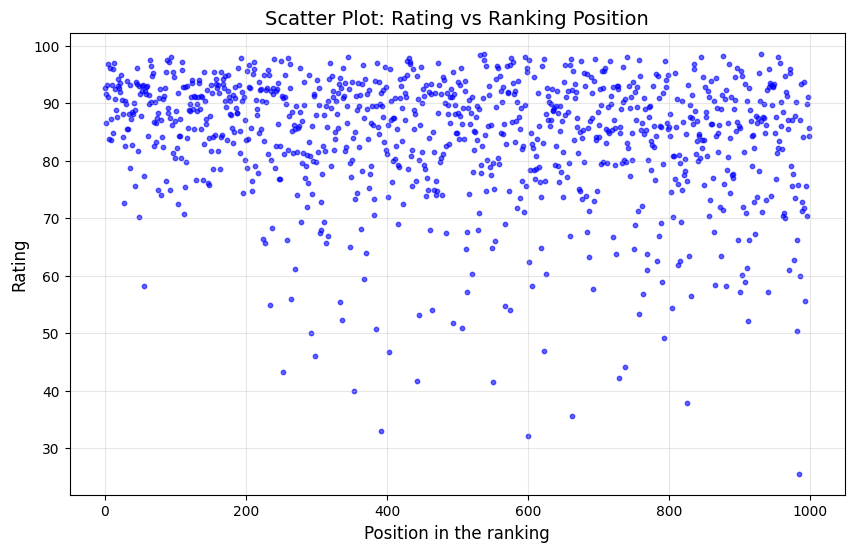

In [5]:
# create scatter plot
plt.figure(figsize=(10,6))
plt.scatter(df.index, df['Rating'], alpha=0.6, color='blue', s=10)

plt.xlabel('Position in the ranking', fontsize=12)
plt.ylabel('Rating', fontsize=12)
plt.title('Scatter Plot: Rating vs Ranking Position', fontsize=14)
plt.grid(True, alpha=0.3)
plt.show()

***2. Evaluate if the data is good or not. Does it have enough samples?***

Answer: As said in class in the tutorial, enough/good data is a minimum of a hundred samples. Here in this dataset, we have a thousand samples, which could be a good indicator for good data. The problem is the data types used in this dataset. Indeed, we have features like active, visits and more which are interpreted as object types, but are in fact integers. The cause is that columns like rank have an "#" character and columns like active, likes and more have a comma ",". This data would be better quality if integers were int64 data types and not interpreted as object types.

***3. How many features does it have? Is it enough?***

Answer: It has only 3 features, and it is not enough. These features only measure the popularity of a game. Important information that could explain a game's rating is missing, such as its genre, creation date, developer, or price of in-game items.

***4. How many samples/observation does it have? Is it enough?***

Answer: It has 1000 samples. It is enough because in class, more than 100 samples is considered good enough.

In [6]:
df.head(5) # print 5 first rows

,Rank,Name,Active,Visits,Favourites,Likes,Dislikes,Rating
0,#1,Blox Fruits,"483,372","41,346,317,182","13,574,097","8,521,670","676,846",92.64
1,#2,Brookhaven 🏡RP,"474,141","55,635,148,446","22,117,653","6,108,763","955,845",86.47
2,#3,Dress To Impress 💜,"297,764","3,876,511,994","3,182,036","2,042,092","188,403",91.55
3,#4,PETS GO! ✨ [NEW],"172,411","145,691,211","199,254","275,267","20,140",93.18
4,#5,Murder Mystery 2,"159,531","18,310,453,247","19,306,585","8,001,198","786,705",91.05


In [7]:
df.tail(2) # print last 2 rows

,Rank,Name,Active,Visits,Favourites,Likes,Dislikes,Rating
998,#999,🏈 Field Goal Simulator,703,"43,992,091","411,025","37,371","6,273",85.63
999,#1000,🎃HALLOWEEN🎃 After The Flash: Wintertide,703,"17,272,456","99,057","27,049","5,060",84.24


In [8]:
df.shape # shows how many rows and columns in the dataset

(1000, 8)

In [9]:
df.describe() # what ever numeric colums it has, it will count the min and max value, and the quartiles

,Rating
count,1000.00000
mean,84.10001
std,11.12230
min,25.55000
25%,79.49500
50%,86.83000
75%,91.99250
max,98.59000


***5. What are the datatypes does the dataset consist of?***

Answer: The dataset consist of object type and float64. To be more precise, rank's real type is ordinal (qualitative) because it has an order. Name is nominal (qualitative) to distinguish the games. Active, Visits, Favourites, Likes and Dislikes are discrete (quantitative) because they are counts. Rating is continuous (quantitative), it's a percentage.

In [10]:
df.info() # shows the datatypes of the features, and how much memory it takes

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Rank        1000 non-null   object 
 1   Name        1000 non-null   object 
 2   Active      1000 non-null   object 
 3   Visits      1000 non-null   object 
 4   Favourites  1000 non-null   object 
 5   Likes       1000 non-null   object 
 6   Dislikes    1000 non-null   object 
 7   Rating      1000 non-null   float64
dtypes: float64(1), object(7)
memory usage: 62.6+ KB


***6. How many columns have null values? If yes, which column, which rows***

Answer: None.

In [11]:
df.isnull() # will show the dataset table with each value being null (true) or not null (false)

,Rank,Name,Active,Visits,Favourites,Likes,Dislikes,Rating
0,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...
995,False,False,False,False,False,False,False,False
996,False,False,False,False,False,False,False,False
997,False,False,False,False,False,False,False,False
998,False,False,False,False,False,False,False,False


In [12]:
df.isnull().sum() # show which colums has null values and how many

,0
Rank,0
Name,0
Active,0
Visits,0
Favourites,0
Likes,0
Dislikes,0
Rating,0


***7. Which column is the feature, which is the target output?***

Answer: Features are active, visits and favourites. The target output is rating. Name is only an identifier and rank is computed from active. Likes and dislikes are not features, because they are used to calculate rating, so it is cheating if we consider them as features.

***8. Does it have missing values? If yes, which column, which row.***

Answer: No, there's none.

***9. What kind of question can be asked, should we ask. Does the dataset suits the question we are asking?***

Answer: The main question we can ask is: Can we predict a game's rating from its popularity (Active, Visits, Favourites)? The dataset only partially suits this question. A popular game does not necessarily have a good rating, and the dataset does not contain information that explains why players like a game (genre, gameplay, update frequency).

Questions the dataset suits well: "Is there a relationship between the number of likes and the number of favourites?" or "Do the most visited games have the most active players?"